In [1]:
# Required libraries
import numpy as np
import pandas as pd
import pickle

# Visualization libraries
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import plotly.express as px

# ML/DL libraries
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# Misc`
import math
from joblib import Parallel, delayed
import PIL
from PIL import Image
import os
import warnings
warnings.filterwarnings('ignore')

2025-10-14 04:44:05.042005: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1760417045.250215      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1760417045.309810      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
# read the metadata
styles = pd.read_csv("/kaggle/input/fashion-product-images-dataset/fashion-dataset/styles.csv", on_bad_lines='skip')
styles.head()

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [3]:
styles.shape

(44424, 10)

In [4]:
# remove a bit unneccesary features
styles.drop(
    ['gender', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName'],
    axis = 1,
    inplace = True
)
styles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44424 entries, 0 to 44423
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   id              44424 non-null  int64 
 1   masterCategory  44424 non-null  object
 2   subCategory     44424 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.0+ MB


In [5]:
styles["masterCategory"].unique()

array(['Apparel', 'Accessories', 'Footwear', 'Personal Care',
       'Free Items', 'Sporting Goods', 'Home'], dtype=object)

In [6]:
len(styles["masterCategory"].unique())

7

In [7]:
# global constants
NUM_CORES = os.cpu_count()
NUMBER_UNIQUE_CATEGORY = styles['masterCategory'].nunique()
BATCH_SIZE = 32
SCALING_SIZE = (64, 64)
SEED_VALUE = 42

In [8]:
# create a dictionary for each master category containing the number of subcategories
subcategory_dict = {}
for category in styles['masterCategory'].unique():
    temp_df = styles[styles['masterCategory'] == category]
    subcategory_dict[category] = temp_df['subCategory'].nunique()
    del temp_df # release memory
subcategory_dict

{'Apparel': 8,
 'Accessories': 20,
 'Footwear': 3,
 'Personal Care': 11,
 'Free Items': 2,
 'Sporting Goods': 2,
 'Home': 1}

In [9]:
# check for imbalance of dataset
pie_values = []
for category in styles['masterCategory'].unique():
    pie_values.append(round(styles[styles['masterCategory'] == category].shape[0] * 100 / styles.shape[0], 2))

fig = px.pie(
    names = styles['masterCategory'].unique(),
    values = pie_values,
    title = 'Percentage of data for each category',
)

fig.update_layout(title_x = 0.5)
fig.show()

In [10]:
class_distribution = styles['masterCategory'].value_counts(normalize=True) * 100
result = pd.DataFrame({
    'Samples': styles['masterCategory'].value_counts(),
    'Percentage': class_distribution.round(2)
})
print(result)

                Samples  Percentage
masterCategory                     
Apparel           21397       48.17
Accessories       11274       25.38
Footwear           9219       20.75
Personal Care      2403        5.41
Free Items          105        0.24
Sporting Goods       25        0.06
Home                  1        0.00


In [11]:
# Giữ lại chỉ 4 class mong muốn
styles = styles[styles['masterCategory'].isin(['Apparel', 'Accessories', 'Footwear'])]
styles = styles.reset_index(drop=True)

# Kiểm tra lại phân bố sau khi lọc
print(styles['masterCategory'].value_counts())

masterCategory
Apparel        21397
Accessories    11274
Footwear        9219
Name: count, dtype: int64


In [12]:
# label encode master category
encoder = LabelEncoder()
styles['masterCategory'] = encoder.fit_transform(styles['masterCategory'])
decoder_dict = {}
for index, _class in enumerate(encoder.classes_):
    decoder_dict[index] = _class

decoder_dict

{0: 'Accessories', 1: 'Apparel', 2: 'Footwear'}

In [13]:
import pickle
print("\n💾 Đã lưu label encoder...")
with open('label_encoder.pkl', 'wb') as f:
    pickle.dump(encoder, f)


💾 Đã lưu label encoder...


In [14]:
# split into train and test
# tách test
X_train, X_test, y_train, y_test = train_test_split(
    styles['id'],
    styles['masterCategory'],
    test_size=0.1,
    random_state=42,
    stratify=styles['masterCategory']  # 🔥 giữ tỉ lệ class
)

# tách validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train  # 🔥 giữ tỉ lệ class
)

# Reset index và chuyển cột id sang kiểu string (để ghép với tên file ảnh).
X_train = X_train.reset_index()
X_train.drop("index", axis = 1, inplace = True)

X_test = X_test.reset_index()
X_test.drop("index", axis = 1, inplace = True)

X_val = X_val.reset_index()
X_val.drop("index", axis = 1, inplace = True)

y_train = y_train.reset_index()
y_train.drop("index", axis = 1, inplace = True)

y_test = y_test.reset_index()
y_test.drop("index", axis = 1, inplace = True)

y_val = y_val.reset_index()
y_val.drop("index", axis = 1, inplace = True)

X_train.head()

,id
0,16109
1,50698
2,6157
3,40505
4,13260


In [15]:
# convert all the ids to string instead of int
X_train['id'] = X_train['id'].apply(str)
X_test['id'] = X_test['id'].apply(str)
X_val['id'] = X_val['id'].apply(str)

X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30160 entries, 0 to 30159
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      30160 non-null  object
dtypes: object(1)
memory usage: 235.8+ KB


In [16]:
class Preprocessing():
    # constructor
    def __init__(self, df, y):
        self.df = df
        self.y = y
        
    # get final dataframe
    def get_final_image(self):
        return (self.df, self.y)
    
    # Loại bỏ ID không có ảnh tương ứng (kiểm tra sự tồn tại của file .jpg trong thư mục images/).
    def remove_non_existing_images(self):
        for _id in self.df['id']:
            path = "/kaggle/input/fashion-product-images-dataset/fashion-dataset/images/" + _id + ".jpg"
            if(not os.path.exists(path)):
                index = self.df[self.df['id'] == _id].index
                self.df.drop(index, inplace = True)
                self.y.drop(index, inplace = True)
                
    # Tạo batch để tải ảnh theo từng nhóm
    def generate_batches(self, batch_size):
        number_of_batches = math.ceil(self.df.shape[0] / batch_size)
        batch_indices = []
        self.batch_size = batch_size
        prev_index = -1
        for index in range(number_of_batches):
            if(index != number_of_batches - 1):
                batch_indices.append((prev_index + 1, prev_index + batch_size))
            else:
                batch_indices.append((prev_index + 1, self.df.shape[0]))
            prev_index += batch_size
        self.batch_indices = batch_indices
        return batch_indices
    
    # load and convert image
    def load_image(self, batch_index):
        loaded_images = np.zeros((self.batch_size, SCALING_SIZE[0], SCALING_SIZE[1]))
        for index, _id in enumerate(self.df['id'].iloc[batch_index[0]:batch_index[1]]):
            path = "/kaggle/input/fashion-product-images-dataset/fashion-dataset/images/" + _id + ".jpg"
            _image = Image.open(path)
            _image = _image.convert('L') # grayscale
            _image = _image.resize(SCALING_SIZE) # resize
            _image = np.asarray(_image)
            loaded_images[index] = _image
        return loaded_images

In [17]:
%%time

# training set proprocessing
training_preprocessor = Preprocessing(X_train, y_train)
training_preprocessor.remove_non_existing_images() #Loại bỏ các mẫu không có ảnh
training_batches = training_preprocessor.generate_batches(BATCH_SIZE)
X_train, y_train = training_preprocessor.get_final_image()

# validation set preprocessing
val_preprocessor = Preprocessing(X_val, y_val)
val_preprocessor.remove_non_existing_images()
val_batches = val_preprocessor.generate_batches(BATCH_SIZE)
X_val, y_val = val_preprocessor.get_final_image()

# test set preprocessing
test_preprocessor = Preprocessing(X_test, y_test)
test_preprocessor.remove_non_existing_images()
test_batches = test_preprocessor.generate_batches(BATCH_SIZE)
X_test, y_test = test_preprocessor.get_final_image()

CPU times: user 412 ms, sys: 1.13 s, total: 1.54 s
Wall time: 1min 47s


In [18]:
# wont be required in future
# done only for 32x32 image

def load_all_images(index, _id):
    path = "/kaggle/input/fashion-product-images-dataset/fashion-dataset/images/" + _id + ".jpg"
    _image = Image.open(path)
    _image = _image.convert('L') # grayscale
    _image = _image.resize(SCALING_SIZE) # resize
    _image = np.asarray(_image)
    return _image

In [19]:
# parallely load all images for individual datasets
# Dùng joblib.Parallel + delayed để tải tất cả ảnh song song trên nhiều CPU cores → tăng tốc độ.
delayed_funcs = [delayed(load_all_images)(index, _id) for index, _id in enumerate(X_train['id'])]
parallel_pool = Parallel(n_jobs=NUM_CORES, backend = 'multiprocessing', verbose = 10)
train_image = parallel_pool(delayed_funcs)

delayed_funcs = [delayed(load_all_images)(index, _id) for index, _id in enumerate(X_val['id'])]
parallel_pool = Parallel(n_jobs=NUM_CORES, backend = 'multiprocessing', verbose = 10)
val_image = parallel_pool(delayed_funcs)

delayed_funcs = [delayed(load_all_images)(index, _id) for index, _id in enumerate(X_test['id'])]
parallel_pool = Parallel(n_jobs=NUM_CORES, backend = 'multiprocessing', verbose = 10)
test_image = parallel_pool(delayed_funcs)

[Parallel(n_jobs=4)]: Using backend MultiprocessingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Batch computation too fast (0.1656332015991211s.) Setting batch_size=2.
[Parallel(n_jobs=4)]: Done     5 out of 30157 | elapsed:    0.6s
[Parallel(n_jobs=4)]: Batch computation too fast (0.12436556816101074s.) Setting batch_size=4.
[Parallel(n_jobs=4)]: Done    12 out of 30157 | elapsed:    0.7s
[Parallel(n_jobs=4)]: Done    28 out of 30157 | elapsed:    0.9s
[Parallel(n_jobs=4)]: Batch computation too fast (0.1859607696533203s.) Setting batch_size=8.
[Parallel(n_jobs=4)]: Done    56 out of 30157 | elapsed:    1.5s
[Parallel(n_jobs=4)]: Done   128 out of 30157 | elapsed:    2.4s
[Parallel(n_jobs=4)]: Done   200 out of 30157 | elapsed:    3.3s
[Parallel(n_jobs=4)]: Done   288 out of 30157 | elapsed:    4.6s
[Parallel(n_jobs=4)]: Done   376 out of 30157 | elapsed:    5.8s
[Parallel(n_jobs=4)]: Done   480 out of 30157 | elapsed:    6.9s
[Parallel(n_jobs=4)]: Done   584 out of 30157 

In [20]:
# Chuẩn hóa dữ liệu
# Chuyển list ảnh → numpy array và chuẩn hóa về [0, 1]
X_train_img = np.array(train_image).reshape(-1, SCALING_SIZE[0], SCALING_SIZE[1], 1) / 255.0
X_val_img   = np.array(val_image).reshape(-1, SCALING_SIZE[0], SCALING_SIZE[1], 1) / 255.0
X_test_img  = np.array(test_image).reshape(-1, SCALING_SIZE[0], SCALING_SIZE[1], 1) / 255.0

# Đảm bảo nhãn là mảng 1D (không phải DataFrame)
y_train_flat = np.asarray(y_train).ravel()
y_val_flat   = np.asarray(y_val).ravel()
y_test_flat  = np.asarray(y_test).ravel()

# Ép kiểu để tiết kiệm bộ nhớ và tương thích TF
X_train_img = X_train_img.astype('float32')
X_val_img   = X_val_img.astype('float32')
X_test_img  = X_test_img.astype('float32')

## **CNN custom**

- Training base

In [21]:
# model building
model = tf.keras.Sequential([
    layers.Conv2D(64, (5, 5), activation='relu', input_shape=(SCALING_SIZE[0], SCALING_SIZE[1], 1)),
    layers.MaxPool2D((2, 2)),
    
    layers.Conv2D(64, (5, 5), activation='relu'),
    layers.MaxPool2D((2, 2)),
    layers.Dropout(0.2),
    
    layers.Flatten(),
    layers.Dense(NUMBER_UNIQUE_CATEGORY, activation='softmax')  # 4 lớp → softmax
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

I0000 00:00:1760417714.921612      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 60, 60, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 64)     │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │        75,719 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 179,847 (702.53 KB)

 Trainable params: 179,847 (702.53 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
%%time

history = model.fit(
    X_train_img,
    y_train_flat,
    epochs=15,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_img, y_val_flat),
    verbose=1
)

Epoch 1/15


I0000 00:00:1760417719.029942      80 service.cc:148] XLA service 0x7ef57800a0d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1760417719.030714      80 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1760417719.265943      80 cuda_dnn.cc:529] Loaded cuDNN version 90300


 36/943 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.5097 - loss: 1.1307

I0000 00:00:1760417721.430579      80 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


943/943 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.8775 - loss: 0.3153 - val_accuracy: 0.9625 - val_loss: 0.1229
Epoch 2/15
943/943 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9669 - loss: 0.1016 - val_accuracy: 0.9740 - val_loss: 0.0919
Epoch 3/15
943/943 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9759 - loss: 0.0762 - val_accuracy: 0.9802 - val_loss: 0.0789
Epoch 4/15
943/943 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9839 - loss: 0.0560 - val_accuracy: 0.9751 - val_loss: 0.0787
Epoch 5/15
943/943 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9861 - loss: 0.0468 - val_accuracy: 0.9755 - val_loss: 0.0821
Epoch 6/15
943/943 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9860 - loss: 0.0432 - val_accuracy: 0.9836 - val_loss: 0.0648
Epoch 7/15
943/943 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9902 - loss: 0.0323 - val_accuracy: 0.9833 - val_loss: 0.0707
Epoch 8/15
943/943 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9913 - loss: 0.0265 - val_accuracy: 0.9796 - val

In [23]:
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score

# Dự đoán trên tập test
y_pred_proba = model.predict(X_test_img)
y_pred = np.argmax(y_pred_proba, axis=1)

# In báo cáo chi tiết theo từng lớp
print("🔍 Classification Report (Test Set):")
print(classification_report(
    y_test_flat, 
    y_pred, 
    target_names=encoder.classes_  
))

# Tính macro-average (không trọng số — phù hợp khi quan tâm đều đến 3 lớp)
f1_macro = f1_score(y_test_flat, y_pred, average='macro')
precision_macro = precision_score(y_test_flat, y_pred, average='macro')
recall_macro = recall_score(y_test_flat, y_pred, average='macro')

print(f"\n📊 Macro-Averaged Metrics:")
print(f"   Precision: {precision_macro:.4f}")
print(f"   Recall:    {recall_macro:.4f}")
print(f"   F1-Score:  {f1_macro:.4f}")

# Đánh giá loss và accuracy từ Keras
test_loss, test_acc = model.evaluate(X_test_img, y_test_flat, verbose=0)
print(f"\n✅ Test Accuracy (Keras): {test_acc:.4f}")

131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
🔍 Classification Report (Test Set):
              precision    recall  f1-score   support

 Accessories       0.95      0.98      0.96      1127
     Apparel       0.99      0.97      0.98      2139
    Footwear       0.99      0.99      0.99       922

    accuracy                           0.98      4188
   macro avg       0.98      0.98      0.98      4188
weighted avg       0.98      0.98      0.98      4188


📊 Macro-Averaged Metrics:
   Precision: 0.9778
   Recall:    0.9830
   F1-Score:  0.9803

✅ Test Accuracy (Keras): 0.9802


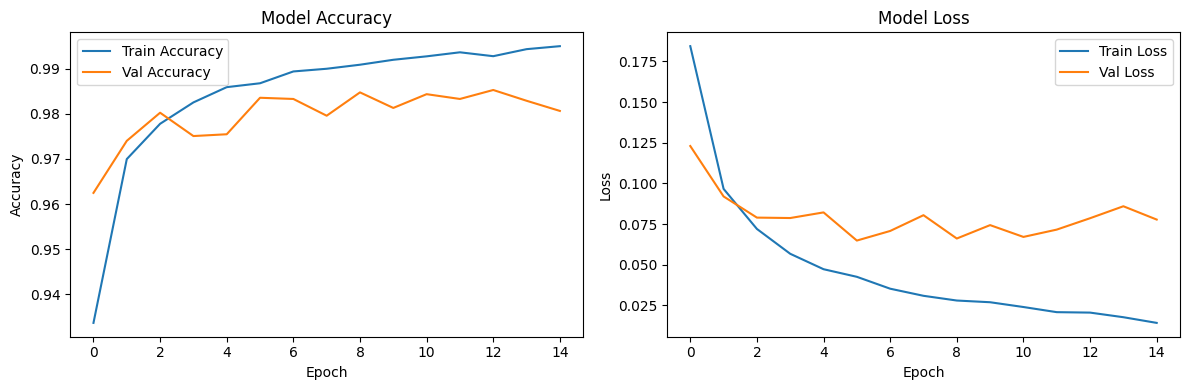

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

- Tăng cường ảnh

In [25]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

In [26]:
datagen = ImageDataGenerator(
    rotation_range=20,           # Xoay ngẫu nhiên ±20 độ
    width_shift_range=0.2,       # Dịch ngang 20%
    height_shift_range=0.2,      # Dịch dọc 20%
    zoom_range=0.15,             # Phóng to/thu nhỏ
    horizontal_flip=True,        # Lật ngang (phù hợp với thời trang)
    fill_mode='nearest'          # Điền pixel bị thiếu bằng giá trị gần nhất
)

In [27]:
# PHÂN TÍCH MỨC ĐỘ MẤT CÂN BẰNG
unique, counts = np.unique(y_train_flat, return_counts=True)
class_distribution = dict(zip(unique, counts))
max_samples = max(counts)

print("📊 Phân bố dữ liệu training:")
for class_idx, count in class_distribution.items():
    class_name = decoder_dict[class_idx]
    print(f"   {class_name} (class {class_idx}): {count} ảnh")
print(f"\n🎯 Mục tiêu: Tăng mỗi class lên {max_samples} ảnh\n")

📊 Phân bố dữ liệu training:
   Accessories (class 0): 8117 ảnh
   Apparel (class 1): 15402 ảnh
   Footwear (class 2): 6638 ảnh

🎯 Mục tiêu: Tăng mỗi class lên 15402 ảnh



In [28]:
# TĂNG CƯỜNG CHO TỪNG CLASS THIỂU SỐ
X_train_augmented = []
y_train_augmented = []

for class_idx in unique:
    # Lấy ảnh của class hiện tại
    class_mask = (y_train_flat == class_idx)
    X_class = X_train_img[class_mask]
    y_class = y_train_flat[class_mask]
    
    # Thêm dữ liệu gốc vào
    X_train_augmented.append(X_class)
    y_train_augmented.append(y_class)
    
    # Tính số ảnh cần tăng cường
    current_count = len(y_class)
    needed_samples = max_samples - current_count
    
    if needed_samples > 0:
        print(f"🔄 Đang tăng cường {decoder_dict[class_idx]}: cần thêm {needed_samples} ảnh...")
        
        # Tạo ảnh tăng cường
        augmented_images = []
        augmented_labels = []
        
        # Sử dụng flow để tạo ảnh mới
        aug_iter = datagen.flow(
            X_class, 
            y_class,
            batch_size=32,
            shuffle=True
        )
        
        # Sinh đủ số lượng ảnh cần thiết
        samples_generated = 0
        while samples_generated < needed_samples:
            batch_x, batch_y = next(aug_iter)
            batch_size = min(len(batch_x), needed_samples - samples_generated)
            
            augmented_images.append(batch_x[:batch_size])
            augmented_labels.append(batch_y[:batch_size])
            samples_generated += batch_size
        
        # Gộp các batch lại
        X_aug = np.concatenate(augmented_images, axis=0)
        y_aug = np.concatenate(augmented_labels, axis=0)
        
        X_train_augmented.append(X_aug)
        y_train_augmented.append(y_aug)
        
        print(f"   ✅ Đã tạo {len(y_aug)} ảnh mới")

# GỘP TẤT CẢ DỮ LIỆU LẠI
X_train_balanced = np.concatenate(X_train_augmented, axis=0)
y_train_balanced = np.concatenate(y_train_augmented, axis=0)

🔄 Đang tăng cường Accessories: cần thêm 7285 ảnh...
   ✅ Đã tạo 7285 ảnh mới
🔄 Đang tăng cường Footwear: cần thêm 8764 ảnh...
   ✅ Đã tạo 8764 ảnh mới


In [29]:
# TRỘN NGẪU NHIÊN DỮ LIỆU
indices = np.arange(len(y_train_balanced))
np.random.shuffle(indices)
X_train_balanced = X_train_balanced[indices]
y_train_balanced = y_train_balanced[indices]

In [30]:
print(f"\n✨ Kết quả:")
print(f"   Dữ liệu gốc: {len(y_train_flat)} ảnh")
print(f"   Dữ liệu sau tăng cường: {len(y_train_balanced)} ảnh")
print(f"\n📊 Phân bố sau cân bằng:")
unique_bal, counts_bal = np.unique(y_train_balanced, return_counts=True)
for class_idx, count in zip(unique_bal, counts_bal):
    print(f"   {decoder_dict[class_idx]}: {count} ảnh")



✨ Kết quả:
   Dữ liệu gốc: 30157 ảnh
   Dữ liệu sau tăng cường: 46206 ảnh

📊 Phân bố sau cân bằng:
   Accessories: 15402 ảnh
   Apparel: 15402 ảnh
   Footwear: 15402 ảnh


In [31]:
# ========================================
# TRAIN MODEL VỚI DỮ LIỆU ĐÃ CÂN BẰNG
# ========================================

# Tạo Data Generator cho training (augmentation real-time)
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Tạo generator
train_generator = train_datagen.flow(
    X_train_balanced,
    y_train_balanced,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# TRAIN MODEL VỚI AUGMENTATION
history = model.fit(
    train_generator,
    steps_per_epoch=len(X_train_balanced) // BATCH_SIZE,
    epochs=15,
    validation_data=(X_val_img, y_val_flat),
    verbose=1
)

print("\n🎉 Hoàn thành training với dữ liệu đã tăng cường!")

Epoch 1/15
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.7482 - loss: 0.6363 - val_accuracy: 0.9394 - val_loss: 0.1882
Epoch 2/15
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 1s 387us/step - accuracy: 0.9375 - loss: 0.1986 - val_accuracy: 0.9402 - val_loss: 0.1856
Epoch 3/15
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 25s 17ms/step - accuracy: 0.8767 - loss: 0.3353 - val_accuracy: 0.9532 - val_loss: 0.1470
Epoch 4/15
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 1s 394us/step - accuracy: 0.8750 - loss: 0.3049 - val_accuracy: 0.9440 - val_loss: 0.1663
Epoch 5/15
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 25s 17ms/step - accuracy: 0.9011 - loss: 0.2716 - val_accuracy: 0.9564 - val_loss: 0.1535
Epoch 6/15
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 1s 392us/step - accuracy: 0.8750 - loss: 0.2351 - val_accuracy: 0.9556 - val_loss: 0.1558
Epoch 7/15
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 25s 17ms/step - accuracy: 0.9205 - loss: 0.2293 - val_accuracy: 0.9611 - val_loss: 0.1380
Epoch 8/15
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 1s 389us/step - accuracy: 1.0000 -

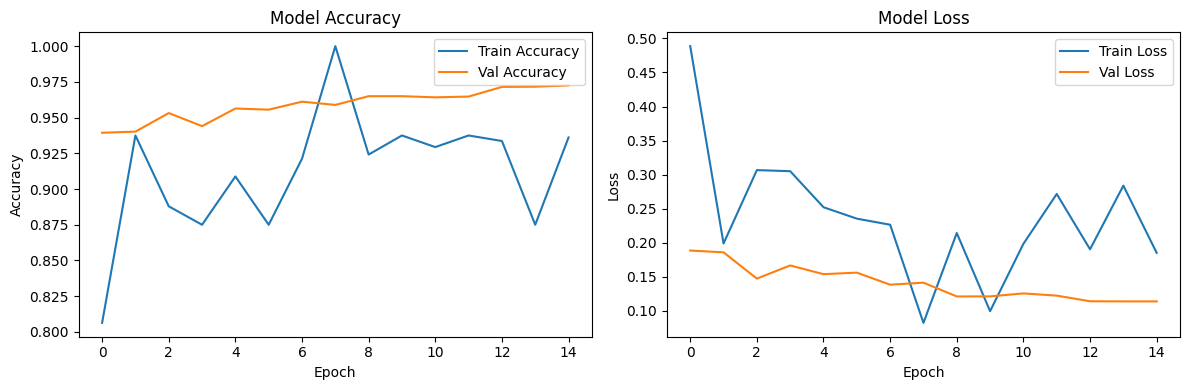

In [32]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [33]:
# Dự đoán trên tập test
print("\n" + "="*60)
print("📈 ĐÁNH GIÁ MODEL TRÊN TẬP TEST")
print("="*60 + "\n")

y_pred_proba = model.predict(X_test_img)
y_pred = np.argmax(y_pred_proba, axis=1)

# In báo cáo chi tiết theo từng lớp
print("🔍 Classification Report (Test Set):")
print(classification_report(
    y_test_flat, 
    y_pred, 
    target_names=encoder.classes_  
))


📈 ĐÁNH GIÁ MODEL TRÊN TẬP TEST

131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
🔍 Classification Report (Test Set):
              precision    recall  f1-score   support

 Accessories       0.96      0.92      0.94      1127
     Apparel       0.97      0.99      0.98      2139
    Footwear       0.98      0.99      0.99       922

    accuracy                           0.97      4188
   macro avg       0.97      0.97      0.97      4188
weighted avg       0.97      0.97      0.97      4188



In [34]:
# Tính macro-average (không trọng số — phù hợp khi quan tâm đều đến 3 lớp)
f1_macro = f1_score(y_test_flat, y_pred, average='macro')
precision_macro = precision_score(y_test_flat, y_pred, average='macro')
recall_macro = recall_score(y_test_flat, y_pred, average='macro')

print(f"\n📊 Macro-Averaged Metrics:")
print(f"   Precision: {precision_macro:.4f}")
print(f"   Recall:    {recall_macro:.4f}")
print(f"   F1-Score:  {f1_macro:.4f}")

# Đánh giá loss và accuracy từ Keras
test_loss, test_acc = model.evaluate(X_test_img, y_test_flat, verbose=0)
print(f"\n✅ Test Accuracy (Keras): {test_acc:.4f}")
print(f"✅ Test Loss: {test_loss:.4f}")


📊 Macro-Averaged Metrics:
   Precision: 0.9716
   Recall:    0.9652
   F1-Score:  0.9682

✅ Test Accuracy (Keras): 0.9697
✅ Test Loss: 0.1016


In [35]:
model.save('fashion_cnn_model.h5')
print("✅ Đã lưu model vào: fashion_cnn_model.h5")

✅ Đã lưu model vào: fashion_cnn_model.h5


## **VGG-16**

In [36]:
def load_all_images_rgb(index, _id):
    path = "/kaggle/input/fashion-product-images-dataset/fashion-dataset/images/" + _id + ".jpg"
    _image = Image.open(path)
    # Chuyển sang RGB (nếu ảnh có alpha hoặc grayscale)
    _image = _image.convert('RGB')  # ← Đảm bảo 3 kênh
    _image = _image.resize(SCALING_SIZE)  # (64, 64)
    _image = np.asarray(_image)  # shape: (64, 64, 3)
    return _image

# Tải lại ảnh dưới dạng RGB
delayed_funcs = [delayed(load_all_images_rgb)(i, _id) for i, _id in enumerate(X_train['id'])]
train_image_rgb = Parallel(n_jobs=NUM_CORES, backend='multiprocessing', verbose=10)(delayed_funcs)

delayed_funcs = [delayed(load_all_images_rgb)(i, _id) for i, _id in enumerate(X_val['id'])]
val_image_rgb = Parallel(n_jobs=NUM_CORES, backend='multiprocessing', verbose=10)(delayed_funcs)

delayed_funcs = [delayed(load_all_images_rgb)(i, _id) for i, _id in enumerate(X_test['id'])]
test_image_rgb = Parallel(n_jobs=NUM_CORES, backend='multiprocessing', verbose=10)(delayed_funcs)

[Parallel(n_jobs=4)]: Using backend MultiprocessingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Batch computation too fast (0.07224154472351074s.) Setting batch_size=2.
[Parallel(n_jobs=4)]: Done     5 out of 30157 | elapsed:    0.6s
[Parallel(n_jobs=4)]: Batch computation too fast (0.13612961769104004s.) Setting batch_size=4.
[Parallel(n_jobs=4)]: Done    12 out of 30157 | elapsed:    0.8s
[Parallel(n_jobs=4)]: Done    28 out of 30157 | elapsed:    1.0s
[Parallel(n_jobs=4)]: Done    56 out of 30157 | elapsed:    1.7s
[Parallel(n_jobs=4)]: Done    92 out of 30157 | elapsed:    2.2s
[Parallel(n_jobs=4)]: Done   128 out of 30157 | elapsed:    2.8s
[Parallel(n_jobs=4)]: Done   172 out of 30157 | elapsed:    3.5s
[Parallel(n_jobs=4)]: Done   216 out of 30157 | elapsed:    4.2s
[Parallel(n_jobs=4)]: Done   268 out of 30157 | elapsed:    5.1s
[Parallel(n_jobs=4)]: Done   320 out of 30157 | elapsed:    5.9s
[Parallel(n_jobs=4)]: Done   380 out of 30157 | elapsed:    7.2s
[Parallel

In [37]:
# Chuyển sang numpy array và chuẩn hóa theo ImageNet (hoặc [0,1])
X_train_vgg = np.array(train_image_rgb).astype('float32')
X_val_vgg   = np.array(val_image_rgb).astype('float32')
X_test_vgg  = np.array(test_image_rgb).astype('float32')

# Cách 1: Chuẩn hóa về [0, 1] → đơn giản, vẫn hiệu quả
X_train_vgg /= 255.0
X_val_vgg   /= 255.0
X_test_vgg  /= 255.0

In [38]:
from tensorflow.keras.applications import VGG16

# Tạo base model (không bao gồm lớp Dense cuối cùng)
base_model = VGG16(
    weights='imagenet',          # Dùng trọng số pretrained
    include_top=False,           # Bỏ lớp FC cuối (1000 class)
    input_shape=(SCALING_SIZE[0], SCALING_SIZE[1], 3)  # (64, 64, 3)
)

# Đóng băng các lớp pretrained (tùy chọn — bạn có thể fine-tune sau)
base_model.trainable = False  # ← Freeze để train nhanh hơn, tránh overfit

# Xây dựng head classifier
model_vgg = tf.keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),  # Thay vì Flatten → giảm số tham số
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(NUMBER_UNIQUE_CATEGORY, activation='softmax')  # 3 lớp
])

# Biên dịch
model_vgg.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_vgg.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 2, 2, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,255 (56.39 MB)

 Trainable params: 66,567 (260.03 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [39]:
%%time

history_vgg = model_vgg.fit(
    X_train_vgg,
    y_train_flat,
    epochs=20,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_vgg, y_val_flat),
    verbose=1
)

Epoch 1/20
943/943 ━━━━━━━━━━━━━━━━━━━━ 21s 18ms/step - accuracy: 0.8772 - loss: 0.3356 - val_accuracy: 0.9668 - val_loss: 0.0995
Epoch 2/20
943/943 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9635 - loss: 0.1080 - val_accuracy: 0.9744 - val_loss: 0.0815
Epoch 3/20
943/943 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9716 - loss: 0.0877 - val_accuracy: 0.9760 - val_loss: 0.0777
Epoch 4/20
943/943 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9763 - loss: 0.0754 - val_accuracy: 0.9781 - val_loss: 0.0706
Epoch 5/20
943/943 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9780 - loss: 0.0686 - val_accuracy: 0.9793 - val_loss: 0.0638
Epoch 6/20
943/943 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9791 - loss: 0.0629 - val_accuracy: 0.9767 - val_loss: 0.0686
Epoch 7/20
943/943 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9810 - loss: 0.0585 - val_accuracy: 0.9813 - val_loss: 0.0596
Epoch 8/20
943/943 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9828 - loss: 0.0541 - 

In [40]:
from sklearn.metrics import classification_report, f1_score, accuracy_score
import numpy as np
import pandas as pd

# Dự đoán
y_pred_vgg = np.argmax(model_vgg.predict(X_test_vgg), axis=1)

# Classification report dưới dạng dict
report_dict = classification_report(y_test_flat, y_pred_vgg, target_names=encoder.classes_, output_dict=True)

# Chuyển sang DataFrame để dễ nhìn
report_df = pd.DataFrame(report_dict).transpose()

# In ra đầy đủ số thực, không làm tròn
pd.set_option('display.float_format', lambda x: '%.6f' % x)
print("🔍 VGG16 - Classification Report (Test Set):")
print(report_df)

# Macro F1
f1_macro = f1_score(y_test_flat, y_pred_vgg, average='macro')
print(f"\n📊 Macro F1-Score: {f1_macro:.6f}")

# Accuracy
acc = accuracy_score(y_test_flat, y_pred_vgg)
print(f"✅ Test Accuracy: {acc:.6f}")


131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step
🔍 VGG16 - Classification Report (Test Set):
              precision   recall  f1-score     support
Accessories    0.974752 0.959184  0.966905 1127.000000
Apparel        0.986916 0.987377  0.987147 2139.000000
Footwear       0.978701 0.996746  0.987641  922.000000
accuracy       0.981853 0.981853  0.981853    0.981853
macro avg      0.980123 0.981102  0.980564 4188.000000
weighted avg   0.981834 0.981853  0.981808 4188.000000

📊 Macro F1-Score: 0.980564
✅ Test Accuracy: 0.981853


In [41]:
model_vgg.save('fashion_vgg16_model.h5')
print("✅ Đã lưu model vào: fashion_vgg16_model.h5")

✅ Đã lưu model vào: fashion_vgg16_model.h5


- Tăng cường ảnh

In [42]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

# 1. TẠO IMAGE DATA GENERATOR VỚI CÁC PHÉP BIẾN ĐỔI CƠ BẢN
datagen = ImageDataGenerator(
    rotation_range=20,           # Xoay ngẫu nhiên ±20 độ
    width_shift_range=0.2,       # Dịch ngang 20%
    height_shift_range=0.2,      # Dịch dọc 20%
    shear_range=0.15,            # Biến dạng nghiêng
    zoom_range=0.15,             # Phóng to/thu nhỏ
    horizontal_flip=True,        # Lật ngang (phù hợp với thời trang)
    fill_mode='nearest'          # Điền pixel bị thiếu bằng giá trị gần nhất
)

In [43]:
# 2. PHÂN TÍCH MỨC ĐỘ MẤT CÂN BẰNG
unique, counts = np.unique(y_train_flat, return_counts=True)
class_distribution = dict(zip(unique, counts))
max_samples = max(counts)

print("📊 Phân bố dữ liệu training:")
for class_idx, count in class_distribution.items():
    class_name = decoder_dict[class_idx]
    print(f"   {class_name} (class {class_idx}): {count} ảnh")
print(f"\n🎯 Mục tiêu: Tăng mỗi class lên {max_samples} ảnh\n")

# 3. TĂNG CƯỜNG CHO TỪNG CLASS THIỂU SỐ
X_train_augmented = []
y_train_augmented = []

for class_idx in unique:
    # Lấy ảnh của class hiện tại
    class_mask = (y_train_flat == class_idx)
    X_class = X_train_vgg[class_mask]
    y_class = y_train_flat[class_mask]
    
    # Thêm dữ liệu gốc vào
    X_train_augmented.append(X_class)
    y_train_augmented.append(y_class)
    
    # Tính số ảnh cần tăng cường
    current_count = len(y_class)
    needed_samples = max_samples - current_count
    
    if needed_samples > 0:
        print(f"🔄 Đang tăng cường {decoder_dict[class_idx]}: cần thêm {needed_samples} ảnh...")
        
        # Tạo ảnh tăng cường
        augmented_images = []
        augmented_labels = []
        
        # Sử dụng flow để tạo ảnh mới
        aug_iter = datagen.flow(
            X_class, 
            y_class,
            batch_size=32,
            shuffle=True
        )
        
        # Sinh đủ số lượng ảnh cần thiết
        samples_generated = 0
        while samples_generated < needed_samples:
            batch_x, batch_y = next(aug_iter)
            batch_size = min(len(batch_x), needed_samples - samples_generated)
            
            augmented_images.append(batch_x[:batch_size])
            augmented_labels.append(batch_y[:batch_size])
            samples_generated += batch_size
        
        # Gộp các batch lại
        X_aug = np.concatenate(augmented_images, axis=0)
        y_aug = np.concatenate(augmented_labels, axis=0)
        
        X_train_augmented.append(X_aug)
        y_train_augmented.append(y_aug)
        
        print(f"   ✅ Đã tạo {len(y_aug)} ảnh mới")

# 4. GỘP TẤT CẢ DỮ LIỆU LẠI
X_train_balanced_vgg = np.concatenate(X_train_augmented, axis=0)
y_train_balanced_vgg = np.concatenate(y_train_augmented, axis=0)

# 5. TRỘN NGẪU NHIÊN DỮ LIỆU
indices = np.arange(len(y_train_balanced_vgg))
np.random.shuffle(indices)
X_train_balanced_vgg = X_train_balanced_vgg[indices]
y_train_balanced_vgg = y_train_balanced_vgg[indices]

📊 Phân bố dữ liệu training:
   Accessories (class 0): 8117 ảnh
   Apparel (class 1): 15402 ảnh
   Footwear (class 2): 6638 ảnh

🎯 Mục tiêu: Tăng mỗi class lên 15402 ảnh

🔄 Đang tăng cường Accessories: cần thêm 7285 ảnh...
   ✅ Đã tạo 7285 ảnh mới
🔄 Đang tăng cường Footwear: cần thêm 8764 ảnh...
   ✅ Đã tạo 8764 ảnh mới


In [44]:
print(f"\n✨ Kết quả:")
print(f"   Dữ liệu gốc: {len(y_train_flat)} ảnh")
print(f"   Dữ liệu sau tăng cường: {len(y_train_balanced_vgg)} ảnh")
print(f"\n📊 Phân bố sau cân bằng:")
unique_bal, counts_bal = np.unique(y_train_balanced_vgg, return_counts=True)
for class_idx, count in zip(unique_bal, counts_bal):
    print(f"   {decoder_dict[class_idx]}: {count} ảnh")


✨ Kết quả:
   Dữ liệu gốc: 30157 ảnh
   Dữ liệu sau tăng cường: 46206 ảnh

📊 Phân bố sau cân bằng:
   Accessories: 15402 ảnh
   Apparel: 15402 ảnh
   Footwear: 15402 ảnh


In [45]:
from tensorflow.keras.applications import VGG16

# Tạo base model (không bao gồm lớp Dense cuối cùng)
base_model = VGG16(
    weights='imagenet',          # Dùng trọng số pretrained
    include_top=False,           # Bỏ lớp FC cuối (1000 class)
    input_shape=(SCALING_SIZE[0], SCALING_SIZE[1], 3)  # (64, 64, 3)
)

# Đóng băng các lớp pretrained (tùy chọn — bạn có thể fine-tune sau)
base_model.trainable = False  # ← Freeze để train nhanh hơn, tránh overfit

# Xây dựng head classifier
model_vgg = tf.keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),  # Thay vì Flatten → giảm số tham số
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(NUMBER_UNIQUE_CATEGORY, activation='softmax')  # 3 lớp
])

# Biên dịch
model_vgg.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_vgg.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 2, 2, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,255 (56.39 MB)

 Trainable params: 66,567 (260.03 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [46]:
# Tạo Data Generator cho training (augmentation real-time)
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Tạo generator
train_generator = train_datagen.flow(
    X_train_balanced_vgg,
    y_train_balanced_vgg,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# TRAIN MODEL
history_vgg = model_vgg.fit(
    train_generator,
    steps_per_epoch=len(X_train_balanced_vgg) // BATCH_SIZE,
    epochs=20,
    validation_data=(X_val_vgg, y_val_flat),
    verbose=1
)

print("\n🎉 Hoàn thành training VGG16 với dữ liệu đã tăng cường!")

Epoch 1/20
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 61s 40ms/step - accuracy: 0.8677 - loss: 0.3573 - val_accuracy: 0.9585 - val_loss: 0.1284
Epoch 2/20
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9375 - loss: 0.1778 - val_accuracy: 0.9582 - val_loss: 0.1287
Epoch 3/20
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 54s 37ms/step - accuracy: 0.9442 - loss: 0.1613 - val_accuracy: 0.9660 - val_loss: 0.1036
Epoch 4/20
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9375 - loss: 0.1136 - val_accuracy: 0.9655 - val_loss: 0.1039
Epoch 5/20
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 54s 38ms/step - accuracy: 0.9531 - loss: 0.1444 - val_accuracy: 0.9675 - val_loss: 0.1006
Epoch 6/20
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8750 - loss: 0.2619 - val_accuracy: 0.9667 - val_loss: 0.1005
Epoch 7/20
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 54s 37ms/step - accuracy: 0.9561 - loss: 0.1250 - val_accuracy: 0.9690 - val_loss: 0.0976
Epoch 8/20
1443/1443 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9688 - loss: 0

In [47]:
from sklearn.metrics import classification_report, f1_score, accuracy_score
import pandas as pd

# Dự đoán
y_pred_vgg = np.argmax(model_vgg.predict(X_test_vgg), axis=1)

# Classification report dưới dạng dict
report_dict = classification_report(y_test_flat, y_pred_vgg, target_names=encoder.classes_, output_dict=True)

# Chuyển sang DataFrame để dễ nhìn
report_df = pd.DataFrame(report_dict).transpose()

# In ra đầy đủ số thực, không làm tròn
pd.set_option('display.float_format', lambda x: '%.6f' % x)
print("🔍 VGG16 - Classification Report (Test Set):")
print(report_df)

131/131 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
🔍 VGG16 - Classification Report (Test Set):
              precision   recall  f1-score     support
Accessories    0.991313 0.911269  0.949607 1127.000000
Apparel        0.958240 0.997662  0.977554 2139.000000
Footwear       0.989189 0.992408  0.990796  922.000000
accuracy       0.973257 0.973257  0.973257    0.973257
macro avg      0.979581 0.967113  0.972652 4188.000000
weighted avg   0.973953 0.973257  0.972949 4188.000000


In [48]:
# Macro F1
f1_macro = f1_score(y_test_flat, y_pred_vgg, average='macro')
print(f"\n📊 Macro F1-Score: {f1_macro:.6f}")

# Accuracy
acc = accuracy_score(y_test_flat, y_pred_vgg)
print(f"✅ Test Accuracy: {acc:.6f}")

# import matplotlib.pyplot as plt
# plt.figure(figsize=(12, 4))
# plt.subplot(1, 2, 1)
# plt.plot(history_vgg.history['accuracy'], label='Train Accuracy')
# plt.plot(history_vgg.history['val_accuracy'], label='Val Accuracy')
# plt.title('Model Accuracy')
# plt.xlabel('Epoch')
# plt.ylabel('Accuracy')
# plt.legend()
# plt.subplot(1, 2, 2)
# plt.plot(history_vgg.history['loss'], label='Train Loss')
# plt.plot(history_vgg.history['val_loss'], label='Val Loss')
# plt.title('Model Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend()
# plt.tight_layout()
# plt.show()


📊 Macro F1-Score: 0.972652
✅ Test Accuracy: 0.973257
